## 1. Setup and EDA Helper Function
Import libraries and define a reusable text-EDA function.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


def text_eda(texts, labels=None):
    """
    Exploratory Data Analysis for Text Classification datasets.

    Parameters
    ----------
    texts : pandas Series or list
        Text documents.

    labels : pandas Series or list, optional
        Target labels.
    """

    texts = pd.Series(texts)

    print("=" * 80)
    print("TEXT DATASET OVERVIEW")
    print("=" * 80)

    print(f"Total Documents : {len(texts)}")

    if labels is not None:
        print(f"Total Labels    : {len(labels)}")

    print()

    # ==========================================================
    # Missing Value Analysis
    # ==========================================================

    print("=" * 80)
    print("MISSING VALUE ANALYSIS")
    print("=" * 80)

    missing = texts.isnull().sum()

    print(f"Missing Documents : {missing}")

    plt.figure(figsize=(4,4))

    plt.bar(["Available","Missing"],
            [len(texts)-missing,missing])

    plt.title("Missing Documents")

    plt.show()

    # ==========================================================
    # Duplicate Analysis
    # ==========================================================

    print("=" * 80)
    print("DUPLICATE ANALYSIS")
    print("=" * 80)

    duplicates = texts.duplicated().sum()

    print(f"Duplicate Documents : {duplicates}")

    plt.figure(figsize=(4,4))

    plt.pie([len(texts)-duplicates,
             duplicates],
            labels=["Unique","Duplicate"],
            autopct="%1.1f%%")

    plt.title("Duplicate Documents")

    plt.show()

    # ==========================================================
    # Text Statistics
    # ==========================================================

    print("=" * 80)
    print("TEXT STATISTICS")
    print("=" * 80)

    temp = texts.fillna("").astype(str)

    word_counts = temp.str.split().apply(len)

    character_counts = temp.str.len()

    sentence_counts = temp.str.count(r"[.!?]") + 1

    print(f"Minimum Words          : {word_counts.min()}")

    print(f"Maximum Words          : {word_counts.max()}")

    print(f"Average Words          : {word_counts.mean():.2f}")

    print(f"Median Words           : {word_counts.median()}")

    print()

    print(f"Average Characters     : {character_counts.mean():.2f}")

    print(f"Average Sentences      : {sentence_counts.mean():.2f}")

    # Word Count Histogram

    plt.figure(figsize=(6,4))

    plt.hist(word_counts,bins=20)

    plt.title("Word Count Distribution")

    plt.xlabel("Words")

    plt.ylabel("Documents")

    plt.show()

    # Character Count Histogram

    plt.figure(figsize=(6,4))

    plt.hist(character_counts,bins=20)

    plt.title("Character Count Distribution")

    plt.xlabel("Characters")

    plt.ylabel("Documents")

    plt.show()

    # ==========================================================
    # Vocabulary Analysis
    # ==========================================================

    print("=" * 80)
    print("VOCABULARY ANALYSIS")
    print("=" * 80)

    words = " ".join(temp.str.lower()).split()

    vocabulary = pd.Series(words)

    vocabulary_size = vocabulary.nunique()

    print(f"Vocabulary Size : {vocabulary_size}")

    print()

    print("Top 20 Frequent Words")

    top_words = vocabulary.value_counts().head(20)

    print(top_words)

    plt.figure(figsize=(10,5))

    top_words.plot(kind="bar")

    plt.title("Top 20 Frequent Words")

    plt.ylabel("Frequency")

    plt.xticks(rotation=45)

    plt.show()

    # ==========================================================
    # Target Analysis
    # ==========================================================

    if labels is not None:

        labels = pd.Series(labels)

        print("=" * 80)
        print("TARGET ANALYSIS")
        print("=" * 80)

        counts = labels.value_counts()

        print(counts)

        plt.figure(figsize=(5,4))

        counts.plot(kind="bar")

        plt.title("Class Distribution")

        plt.ylabel("Count")

        plt.show()

        ratio = counts.max()/counts.min()

        if ratio > 1.5:
            balance = "Imbalanced"
        else:
            balance = "Balanced"

    else:

        balance = "N/A"

    # ==========================================================
    # FINAL SUMMARY
    # ==========================================================

    print()
    print("=" * 80)
    print("FINAL TEXT EDA SUMMARY")
    print("=" * 80)

    print(f"Total Documents        : {len(texts)}")

    print(f"Missing Documents      : {missing}")

    print(f"Duplicate Documents    : {duplicates}")

    print(f"Vocabulary Size        : {vocabulary_size}")

    print(f"Average Words          : {word_counts.mean():.2f}")

    print(f"Average Characters     : {character_counts.mean():.2f}")

    print(f"Average Sentences      : {sentence_counts.mean():.2f}")

    print(f"Class Balance          : {balance}")

    print()

    print("EDA Completed Successfully.")

## 2. Load Dataset

In [ ]:
spam=pd.read_csv("datasets\email\spam.csv")
spam.head()


,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## 3. Exploratory Data Analysis

TEXT DATASET OVERVIEW
Total Documents : 5572
Total Labels    : 5572

MISSING VALUE ANALYSIS
Missing Documents : 0


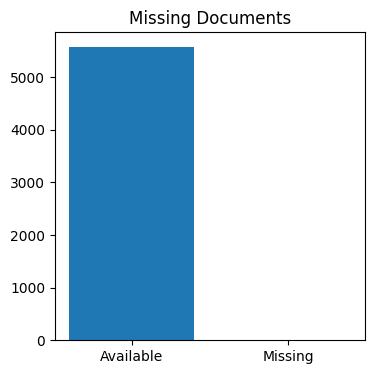

DUPLICATE ANALYSIS
Duplicate Documents : 415


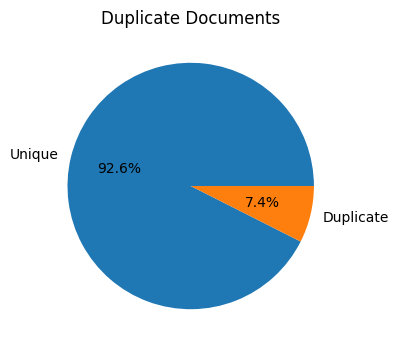

TEXT STATISTICS
Minimum Words          : 1
Maximum Words          : 171
Average Words          : 15.58
Median Words           : 12.0

Average Characters     : 80.37
Average Sentences      : 3.54


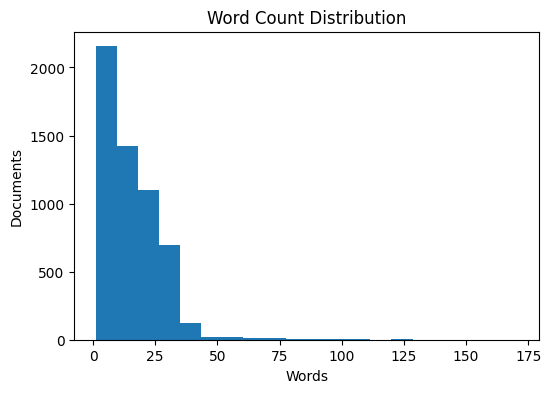

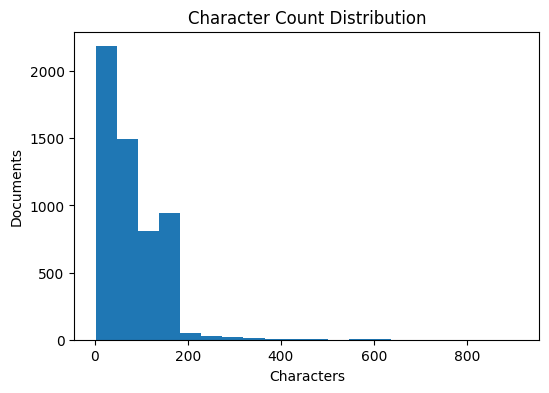

VOCABULARY ANALYSIS
Vocabulary Size : 13574

Top 20 Frequent Words
to      2234
i       2217
you     1921
a       1433
the     1326
u        996
and      968
is       868
in       857
my       755
for      704
your     677
of       614
me       611
have     568
call     556
on       521
are      487
that     470
it       466
Name: count, dtype: int64


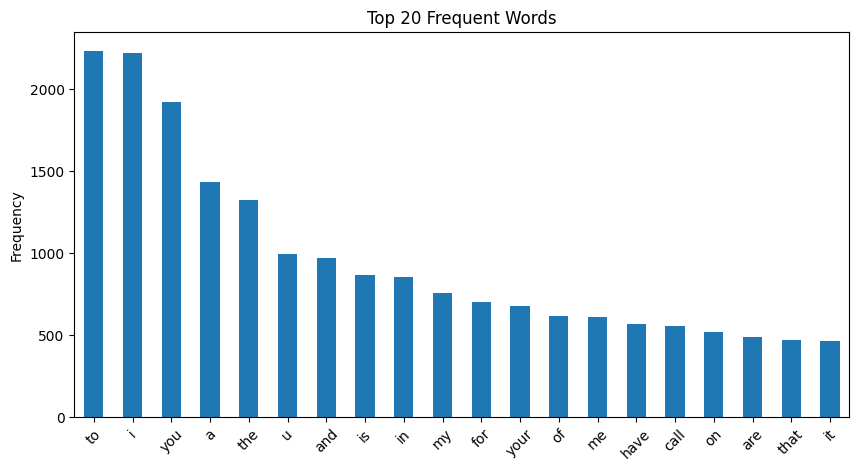

TARGET ANALYSIS
Category
ham     4825
spam     747
Name: count, dtype: int64


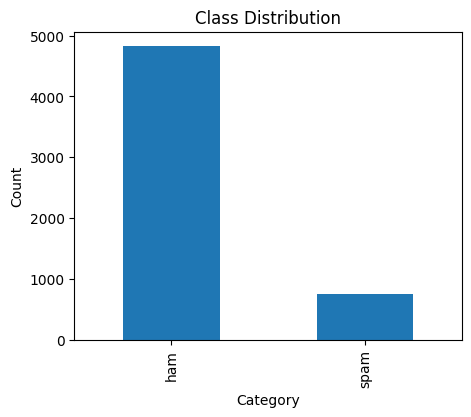


FINAL TEXT EDA SUMMARY
Total Documents        : 5572
Missing Documents      : 0
Duplicate Documents    : 415
Vocabulary Size        : 13574
Average Words          : 15.58
Average Characters     : 80.37
Average Sentences      : 3.54
Class Balance          : Imbalanced

EDA Completed Successfully.


In [ ]:
text_eda(
    texts=spam["Message"],
    labels=spam["Category"]
)

## 4. Data Preprocessing
Remove duplicate messages, clean the text, convert it into numeric features using TF-IDF, and encode the target label.

In [ ]:
spam = spam.drop_duplicates()

In [ ]:
spam.duplicated().sum()


np.int64(0)

In [ ]:
import re
import string
from nltk.corpus import stopwords
import nltk

nltk.download('stopwords')

stop_words = set(stopwords.words("english"))

def preprocess_text(text):

    # Convert to lowercase
    text = text.lower()

    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))

    # Remove numbers
    text = re.sub(r'\d+', '', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    # Remove stopwords
    words = text.split()
    words = [word for word in words if word not in stop_words]

    return " ".join(words)

spam["Processed_Message"] = spam["Message"].apply(preprocess_text)

spam[["Message", "Processed_Message"]].head()

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


,Message,Processed_Message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,"Nah I don't think he goes to usf, he lives aro...",nah dont think goes usf lives around though


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()

X = tfidf.fit_transform(spam["Processed_Message"])

y = spam["Category"]

In [ ]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

y = encoder.fit_transform(y)

## 5. Train-Test Split

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

## 6. Model Training and Evaluation

========== Multinomial Naive Bayes ==========
Accuracy : 0.9573643410852714
Precision: 1.0
Recall   : 0.65625
F1 Score : 0.7924528301886793


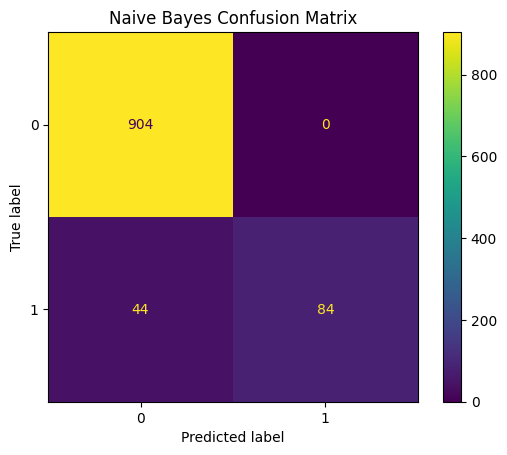

In [ ]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

nb = MultinomialNB()

nb.fit(X_train, y_train)

y_pred_nb = nb.predict(X_test)

print("========== Multinomial Naive Bayes ==========")

print("Accuracy :", accuracy_score(y_test, y_pred_nb))
print("Precision:", precision_score(y_test, y_pred_nb))
print("Recall   :", recall_score(y_test, y_pred_nb))
print("F1 Score :", f1_score(y_test, y_pred_nb))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_nb)
plt.title("Naive Bayes Confusion Matrix")
plt.show()

========== Logistic Regression ==========
Accuracy : 0.9534883720930233
Precision: 0.9651162790697675
Recall   : 0.6484375
F1 Score : 0.7757009345794392


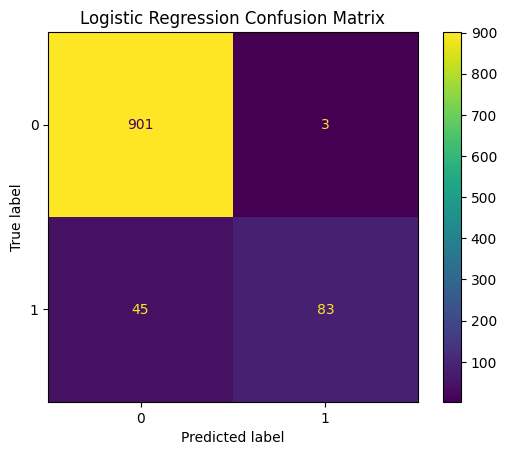

In [ ]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000)

lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

print("========== Logistic Regression ==========")

print("Accuracy :", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall   :", recall_score(y_test, y_pred_lr))
print("F1 Score :", f1_score(y_test, y_pred_lr))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr)
plt.title("Logistic Regression Confusion Matrix")
plt.show()